# Grover's Algorithm — A Beginner's Introduction

**CPE 708 · Quantum Computing and Emerging Technologies**

Grover's algorithm searches an unsorted list faster than any classical algorithm can. This notebook builds it from scratch, two qubits at a time, so every gate maps directly to something you can picture: a coin flip into superposition, a sign flip on the answer, and a reflection that turns that sign flip into a real boost in probability.

**What we'll do:**
1. Put 4 possible answers into equal superposition
2. Build the **oracle** — the gate that marks the correct answer with a flipped sign
3. Build the **diffuser** — the gate that turns that sign flip into higher probability
4. Run one full Grover iteration and watch the marked answer jump to ~100%
5. See what happens if we iterate *too many* times
6. Measure the circuit for real, with shots, like on actual hardware

## The Problem: Searching an Unsorted List

Imagine 4 boxes, numbered `00`, `01`, `10`, `11`. Exactly one of them hides the answer you want, and nothing distinguishes the boxes from the outside — you have to open them to check.

- **Classically**, in the worst case you check boxes one at a time: up to N = 4 checks.
- **Grover's algorithm** finds it in about √N ≈ 2 steps — and for larger N, the gap grows: a million items would take a classical computer up to 1,000,000 checks, but Grover needs only about 1,000.

This notebook builds that speedup for N = 4 (2 qubits) — small enough to compute by hand, large enough to see the real effect.

In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
import matplotlib.pyplot as plt
import numpy as np

LABELS = ['00', '01', '10', '11']

def probs_bar(probabilities, title, highlight=None):
    colors = ['#6A171F' if lbl == highlight else '#C9A227' for lbl in LABELS]
    plt.figure(figsize=(5, 3))
    plt.bar(LABELS, probabilities, color=colors)
    plt.ylim(0, 1.05)
    plt.ylabel('Probability')
    plt.title(title)
    for i, p in enumerate(probabilities):
        plt.text(i, p + 0.02, f'{p:.2f}', ha='center')
    plt.tight_layout()
    plt.show()

## Step 1 — Superposition: An Equal Guess for Every Box

Before we know anything, every box is equally likely to be the answer. Two Hadamard gates put our 2 qubits into an equal superposition of all 4 basis states — `00`, `01`, `10`, `11` — each with probability 1/4.

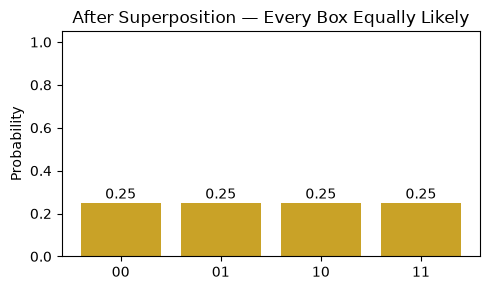

In [2]:
qc = QuantumCircuit(2)
qc.h([0, 1])

state = Statevector(qc)
probs_bar(state.probabilities(), 'After Superposition — Every Box Equally Likely')

## Step 2 — The Oracle: Marking the Answer

The oracle doesn't tell us *which* box is the answer out loud — it flips the **sign** of that one state's amplitude, leaving its probability (which depends on the amplitude *squared*) completely unchanged. That flipped sign is invisible if you measure right now, but it's exactly what the next step needs.

To mark an arbitrary 2-bit target (say `'10'`): flip any qubit whose target bit is `0` with an `X` gate, apply a controlled-Z so only the all-ones state picks up a minus sign, then undo the `X` gates. The net effect is a minus sign on exactly the target state and nothing else.

Amplitudes after the oracle: [ 0.5  0.5 -0.5  0.5]


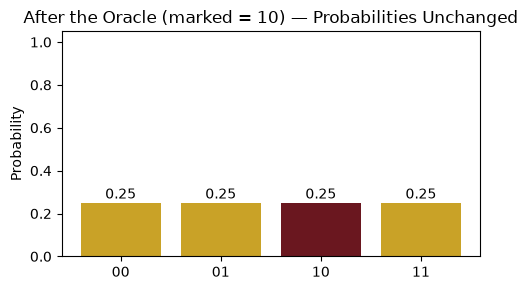

In [3]:
def oracle(qc, marked):
    # Flip the sign of the `marked` 2-bit state (e.g. '10'), leave everything else alone.
    for qubit, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(qubit)
    qc.cz(0, 1)
    for qubit, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(qubit)

MARKED = '10'  # <- the box we're looking for. Try changing this later!

qc = QuantumCircuit(2)
qc.h([0, 1])
oracle(qc, MARKED)

state = Statevector(qc)
print('Amplitudes after the oracle:', np.round(state.data.real, 3))
probs_bar(state.probabilities(), f'After the Oracle (marked = {MARKED}) — Probabilities Unchanged', highlight=MARKED)

Notice the probabilities above look identical to Step 1 — because squaring a negative amplitude gives the same probability as squaring a positive one. Print the amplitudes (not the probabilities) and you'll see the marked state is now **negative**. That hidden minus sign is the whole trick.

## Step 3 — The Diffuser: Turning a Sign Flip Into a Real Boost

The diffuser reflects every amplitude about their **average**. Once one amplitude is negative and the rest are positive, that average sits a little below the positive amplitudes and a little above the negative one — so reflecting about it pushes the marked (negative) amplitude *up* and nudges the others *down*.

For 2 qubits, "reflect about the average" is built from: `H`, `X` on both qubits, a controlled-Z, `X` again, then `H` again.

In [4]:
def diffuser(qc):
    # Reflect both qubits' amplitudes about their average (2-qubit case).
    qc.h([0, 1])
    qc.x([0, 1])
    qc.cz(0, 1)
    qc.x([0, 1])
    qc.h([0, 1])

## Step 4 — One Full Grover Iteration

One Grover iteration = **oracle** then **diffuser**. Let's run exactly one iteration on our 4-box problem and see what happens to the marked state's probability.

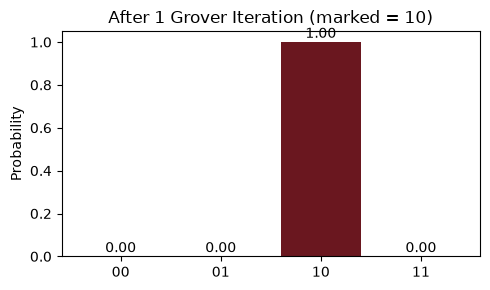

P(10) = 1.000


In [5]:
qc = QuantumCircuit(2)
qc.h([0, 1])          # Step 1: superposition
oracle(qc, MARKED)    # Step 2: mark the answer
diffuser(qc)          # Step 3: amplify it

state = Statevector(qc)
probs_bar(state.probabilities(), f'After 1 Grover Iteration (marked = {MARKED})', highlight=MARKED)
print(f'P({MARKED}) = {state.probabilities_dict()[MARKED]:.3f}')

For N = 4, a single iteration takes the marked box's probability from 25% all the way to (almost exactly) **100%**. That's the speedup: one round of "mark, then amplify" instead of checking boxes one at a time.

## Step 5 — What If We Iterate *Too Many* Times?

More iterations isn't always better. Each additional oracle + diffuser round keeps rotating the state — and once it passes the peak, probability starts flowing *back out* of the marked state. Let's sweep the iteration count and watch.

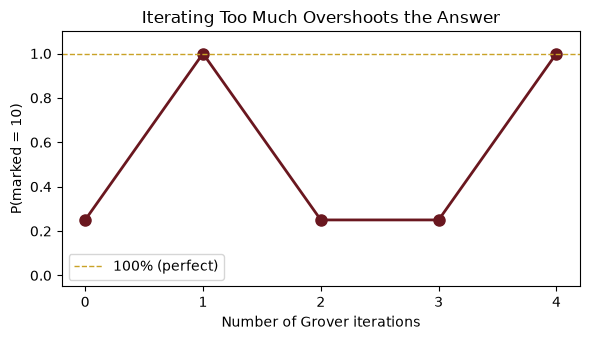

0 iteration(s): P(marked) = 0.250
1 iteration(s): P(marked) = 1.000
2 iteration(s): P(marked) = 0.250
3 iteration(s): P(marked) = 0.250
4 iteration(s): P(marked) = 1.000


In [6]:
def grover_circuit(marked, iterations):
    qc = QuantumCircuit(2)
    qc.h([0, 1])
    for _ in range(iterations):
        oracle(qc, marked)
        diffuser(qc)
    return qc

iteration_counts = [0, 1, 2, 3, 4]
marked_probs = []
for n in iteration_counts:
    qc = grover_circuit(MARKED, n)
    state = Statevector(qc)
    marked_probs.append(state.probabilities_dict()[MARKED])

plt.figure(figsize=(6, 3.5))
plt.plot(iteration_counts, marked_probs, 'o-', color='#6A171F', linewidth=2, markersize=8)
plt.axhline(1.0, color='#C9A227', linestyle='--', linewidth=1, label='100% (perfect)')
plt.xlabel('Number of Grover iterations')
plt.ylabel(f'P(marked = {MARKED})')
plt.title('Iterating Too Much Overshoots the Answer')
plt.ylim(-0.05, 1.1)
plt.xticks(iteration_counts)
plt.legend()
plt.tight_layout()
plt.show()

for n, p in zip(iteration_counts, marked_probs):
    print(f'{n} iteration(s): P(marked) = {p:.3f}')

For N = 4, iteration 1 is exactly the optimal stopping point — iteration 2 already overshoots back down. In general, the optimal number of iterations is approximately **π/4 · √N**, rounded to the nearest whole number — for N = 4, that's π/4 · 2 ≈ 1.57, which rounds to 1.

## Step 6 — Measuring for Real

Everything above used the exact statevector — the "ideal math" answer. On real hardware (or a shot-based simulator) you don't get exact probabilities; you get a fixed number of measurement **shots**, each one a single random outcome. Let's run our optimal 1-iteration circuit that way, with measurement included.

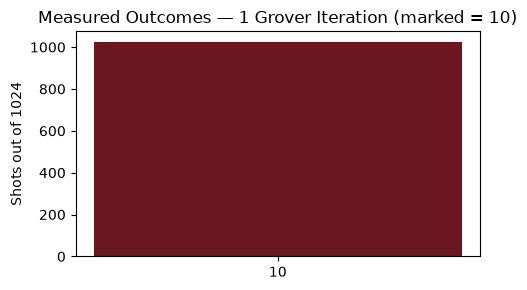

{'10': 1024}


In [7]:
qc = grover_circuit(MARKED, iterations=1)
qc.measure_all()

sampler = StatevectorSampler()
job = sampler.run([qc], shots=1024)
counts = job.result()[0].data.meas.get_counts()

plt.figure(figsize=(5, 3))
plt.bar(counts.keys(), counts.values(), color='#6A171F')
plt.ylabel('Shots out of 1024')
plt.title(f'Measured Outcomes — 1 Grover Iteration (marked = {MARKED})')
plt.tight_layout()
plt.show()

print(counts)

Almost every one of the 1024 shots lands on `10` — exactly the box we marked, found in a single Grover iteration instead of checking boxes one at a time.

## Try It Yourself

1. Scroll back up to the cell that sets `MARKED = '10'`, change it to `'00'`, `'01'`, or `'11'`, and re-run every cell below it. The algorithm finds whichever box you mark, every time, in 1 iteration.
2. In Step 5's sweep, try adding more iteration counts (e.g. `[0, 1, 2, 3, 4, 5, 6]`) and see the probability oscillate again on its way back up.

## Recap

- **Superposition** gives every possible answer an equal starting probability.
- The **oracle** marks the correct answer with a flipped sign — invisible to a measurement taken right then, but essential for the next step.
- The **diffuser** reflects every amplitude about their average, turning that hidden sign flip into a real jump in probability.
- One oracle + diffuser pair is one **Grover iteration**; the right number of iterations is about π/4 · √N — too few under-amplifies, too many overshoots back down.
- For N = 4, exactly **1 iteration** takes the marked answer from 25% to essentially 100% probability — a real quantum speedup over checking boxes one at a time, demonstrated here on real Qiskit circuits.